# 05 · Team strength & fixture difficulty

This notebook answers your questions from notebook 00: **how do we measure fixture difficulty, does home/away matter, and
does difficulty change every gameweek?**

## The idea
Every team gets two numbers, re-estimated **before every gameweek deadline** from recent matches:
- **attack**: how many goals (expected goals) it creates compared with an average team;
- **defence**: how few it concedes compared with an average team.

For any fixture, team A's expected goals are

`λ_A = league baseline × home bonus (if at home) × A's attack × B's defensive weakness`

and team B's **clean-sheet probability** is the chance A scores zero: `P(CS_B) = e^(−λ_A)` (a Poisson model).

Older matches count less (exponential decay with a **half-life**). Promoted teams get their own adjustment, since they have
no Premier League history.

Code: [`fpl_engine/models/team_strength.py`](../fpl_engine/models/team_strength.py)

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from fpl_engine import db
from fpl_engine.models import team_strength as ts
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 200)
with db.connect() as conn:
    m = ts.load_matches(conn)
    names = dict(conn.execute('SELECT team_id, COALESCE(short_name, team_name) FROM core.teams').fetchall())
print(f"{m.played.sum()} played matches since 2021-22; {(~m.played).sum()} still to play")

2000 played matches since 2021-22; 280 still to play


## 1 · Which "expected goals"?

We have two xG sources per match: **PitchAPI's team xG** and the **sum of FPL's player xG**. They're different xG
models. PitchAPI's tracks actual goals more closely and covers 2021-22, where FPL has no xG.

In [2]:
e = m[m.played & m.h_xg_fpl.notna()]
pd.DataFrame({'avg home xG': [e.h_xg_pa.mean(), e.h_xg_fpl.mean(), e.home_score.mean()],
              'corr with goals': [e.h_xg_pa.corr(e.home_score), e.h_xg_fpl.corr(e.home_score), 1.0]},
             index=['PitchAPI team xG', 'FPL player xG summed', 'actual goals']).round(3)

,avg home xG,corr with goals
PitchAPI team xG,1.612,0.559
FPL player xG summed,1.489,0.446
actual goals,1.613,1.000


## 2 · Backtest: does it predict future goals and clean sheets?

Same rolling-origin rule as before: before each gameweek (2024-25 onwards), fit on earlier matches only, predict that
gameweek. Two measures:
- **goal log-likelihood**: how much probability the model gave to the score that actually happened (*higher = better*).
- **clean-sheet Brier**: squared error of P(clean sheet) (*lower = better*).

Baselines: **league average** (every team is average) and the **official FPL difficulty (FDR) lookup** (average goals and
clean-sheet rate for each official 1–5 rating, home/away).

In [3]:
rows = [{'model': 'league average', **ts.evaluate(m, ts.rolling_baseline(m, ts.LeagueAverage()))},
        {'model': 'official FDR lookup', **ts.evaluate(m, ts.rolling_baseline(m, ts.FdrLookup()))}]
grid = [('pa', 1.0, 60), ('pa', 1.0, 180), ('pa', 1.0, 365), ('pa', 1.0, 540),
        ('fpl', 1.0, 365), ('pa', 0.7, 365), ('pa', 0.0, 365)]
for src, w, hl in grid:
    p = ts.rolling_predictions(m, ts.TeamStrengthConfig(source=src, xg_weight=w, half_life_days=hl, window_days=1095),
                               from_season='2024-25')
    rows.append({'model': f'ratings · {src} xG · xG weight {w} · half-life {hl}d', **ts.evaluate(m, p)})
res = pd.DataFrame(rows).set_index('model')
res.sort_values('goal log-lik', ascending=False).round(4)

,goal log-lik,goal MAE,CS Brier,fixtures
model,,,,
ratings · pa xG · xG weight 1.0 · half-life 540d,-1.4553,0.9016,0.1766,860
ratings · pa xG · xG weight 1.0 · half-life 365d,-1.4554,0.9023,0.1767,860
ratings · fpl xG · xG weight 1.0 · half-life 365d,-1.4560,0.9005,0.1772,860
ratings · pa xG · xG weight 0.7 · half-life 365d,-1.4570,0.9041,0.1767,860
ratings · pa xG · xG weight 1.0 · half-life 180d,-1.4580,0.9055,0.1775,860
ratings · pa xG · xG weight 0.0 · half-life 365d,-1.4695,0.9164,0.1781,860
ratings · pa xG · xG weight 1.0 · half-life 60d,-1.4727,0.9164,0.1807,860
official FDR lookup,-1.4843,0.9452,0.1833,860
league average,-1.5078,0.9787,0.1880,860


What this says:
- **Our ratings clearly beat both baselines**: the official FDR lookup and "every team is average", on goals *and* clean
  sheets. And the FDR lookup is if anything *flattered*: our historical FDR values were captured at the end of each
  season (or today), so they already "know" how strong teams turned out to be.
- **xG beats actual goals** as the thing to learn from (xG weight 1.0 > 0.7 > 0.0): goals are noisy, xG is steadier.
- **A long memory works best**: a half-life of about **a year**, using up to 3 seasons. Team quality is fairly
  persistent; short memories over-react to a few lucky or unlucky games.
- The two xG sources are close; **PitchAPI's** has a slight edge and covers 2021-22.
- Football scores are very random, so differences in log-likelihood look small. What matters is that they're consistent.

> 🐞 *A note on honesty:* the first version of this model had a bug: the team indicators were silently not being set
> (a pandas copy-on-write subtlety), so it was really just "home advantage + promoted". The backtest exposed it: the
> fixed version improved goal log-likelihood from −1.483 to −1.455 and now beats FDR clearly.

ent.

## 3 · Does home/away matter?

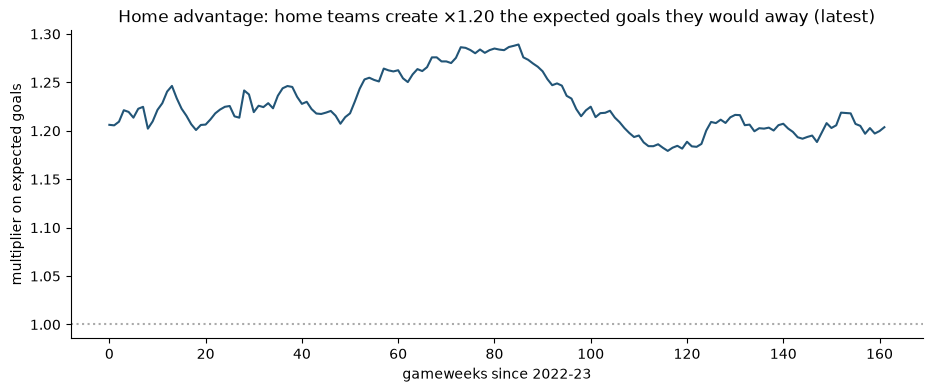

In [4]:
cfg = ts.TeamStrengthConfig(source='pa', xg_weight=1.0, half_life_days=365, window_days=1095)
model = ts.TeamStrength(cfg)
deadlines = m[m.season >= '2022-23'].groupby('gw_key').deadline.min()
deadlines = deadlines[deadlines < pd.Timestamp.now(tz='UTC')]
traj = []
for gw_key, dl in deadlines.items():
    model.fit(m, dl)
    r = model.ratings().assign(gw_key=gw_key, home_adv=model.home_advantage)
    traj.append(r)
traj = pd.concat(traj).reset_index(names='team_id')
ha = traj.drop_duplicates('gw_key').set_index('gw_key').home_adv
ax = ha.reset_index(drop=True).plot(color='#257'); ax.axhline(1, color='#aaa', ls=':')
ax.set_title(f'Home advantage: home teams create ×{ha.iloc[-1]:.2f} the expected goals they would away (latest)')
ax.set_ylabel('multiplier on expected goals'); ax.set_xlabel('gameweeks since 2022-23'); plt.show()

**Yes, home/away matters:** a team at home creates roughly **15–25% more expected goals** than the same team away
(and its opponent correspondingly fewer). It's re-estimated every gameweek rather than hard-coded; home advantage is known
to vary between seasons (it nearly vanished in the empty-stadium COVID season).

## 4 · Does difficulty change every gameweek?

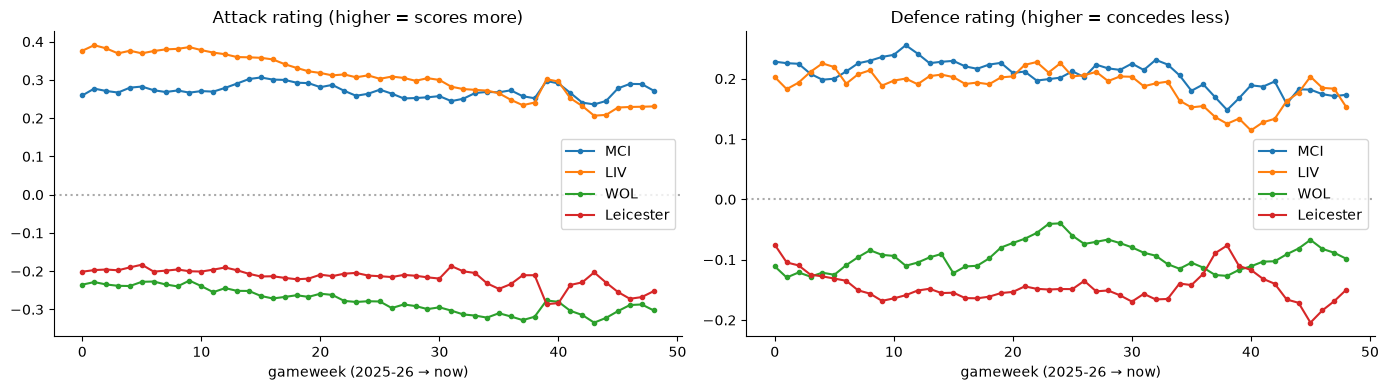

In [5]:
recent = traj[traj.gw_key >= 202500].copy()
recent['team'] = recent.team_id.map(names)
latest = recent[recent.gw_key == recent.gw_key.max()].set_index('team')
pick = list(latest.attack.nlargest(2).index) + list(latest.attack.nsmallest(2).index)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col, title in [(axes[0], 'attack', 'Attack rating (higher = scores more)'),
                       (axes[1], 'defence', 'Defence rating (higher = concedes less)')]:
    for t in pick:
        s = recent[recent.team == t].set_index('gw_key')[col]
        ax.plot(range(len(s)), s.values, marker='.', label=t)
    ax.axhline(0, color='#aaa', ls=':'); ax.set_title(title); ax.set_xlabel('gameweek (2025-26 → now)'); ax.legend()
plt.tight_layout(); plt.show()

**Yes:** ratings move after every gameweek as new matches come in, and the moves are biggest when a team's underlying
numbers change (new manager, injuries). FPL's official FDR, by contrast, changes rarely and only in whole steps of 1–5.

## 5 · Next gameweek's fixtures, by position

Difficulty is **position-specific** (as the spec asks): a defender cares about **clean-sheet probability**, an attacker about
**expected goals for his team**.

In [6]:
upcoming_key = m.loc[~m.played, 'gw_key'].min()
fx = m[m.gw_key == upcoming_key]
model.fit(m, min(fx.deadline.min(), pd.Timestamp.now(tz='UTC')))
p = model.predict(fx).merge(fx[['fixture_id', 'home_team_id', 'away_team_id', 'official_home_fdr', 'official_away_fdr']])
view = pd.concat([
    pd.DataFrame({'team': p.home_team_id.map(names), 'opponent': p.away_team_id.map(names) + ' (H)',
                  'xG for (attackers)': p.lam_home, 'xG against': p.lam_away, 'clean sheet % (GK/DEF)': 100 * p.p_cs_home,
                  'official FDR': p.official_home_fdr}),
    pd.DataFrame({'team': p.away_team_id.map(names), 'opponent': p.home_team_id.map(names) + ' (A)',
                  'xG for (attackers)': p.lam_away, 'xG against': p.lam_home, 'clean sheet % (GK/DEF)': 100 * p.p_cs_away,
                  'official FDR': p.official_away_fdr})])
print(f"Gameweek {fx.gameweek.iloc[0]} of {fx.season.iloc[0]}")
view.sort_values('clean sheet % (GK/DEF)', ascending=False).round(2).reset_index(drop=True)

Gameweek 11 of 2026-27


,team,opponent,xG for (attackers),xG against,clean sheet % (GK/DEF),official FDR
0,ARS,NEW (A),1.53,0.96,38.18,3
1,TOT,IPS (H),1.84,1.01,36.58,2
2,MCI,FUL (H),1.96,1.01,36.53,2
3,BHA,HUL (A),1.48,1.02,35.96,2
4,BOU,NFO (H),1.74,1.12,32.68,3
5,BRE,EVE (H),1.67,1.18,30.83,3
6,CRY,COV (A),1.53,1.22,29.45,2
7,LIV,MUN (H),2.04,1.26,28.37,3
8,AVL,SUN (H),1.41,1.38,25.15,2
9,SUN,AVL (A),1.38,1.41,24.49,3


Read across: the top rows are the best defensive fixtures; sort by **xG for** for the best attacking ones. Where our
numbers and the official FDR disagree, the official rating is usually lagging behind recent form.

## 6 · Clean-sheet calibration

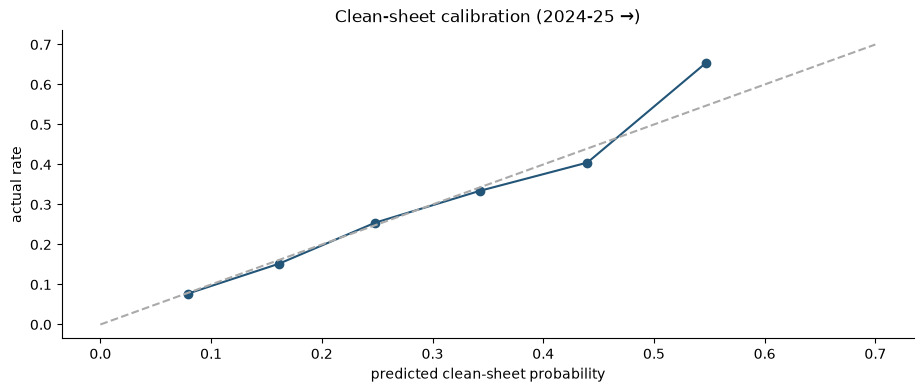

,pred,actual,n
p,,,
"(0.0, 0.1]",0.079,0.077,78
"(0.1, 0.2]",0.161,0.152,520
"(0.2, 0.3]",0.248,0.255,605
"(0.3, 0.4]",0.343,0.334,365
"(0.4, 0.5]",0.440,0.405,126
"(0.5, 0.7]",0.547,0.654,26


In [7]:
p_all = ts.rolling_predictions(m, cfg, from_season='2024-25')
e = m[m.played].merge(p_all, on='fixture_id')
d = pd.DataFrame({'p': pd.concat([e.p_cs_home, e.p_cs_away]),
                  'y': pd.concat([e.away_score == 0, e.home_score == 0]).astype(float)})
cal = d.groupby(pd.cut(d.p, [0, .1, .2, .3, .4, .5, .7, 1]), observed=True).agg(pred=('p', 'mean'), actual=('y', 'mean'), n=('y', 'size'))
ax = cal.plot(x='pred', y='actual', marker='o', legend=False, color='#257'); ax.plot([0, .7], [0, .7], '--', color='#aaa')
ax.set_xlabel('predicted clean-sheet probability'); ax.set_ylabel('actual rate'); ax.set_title('Clean-sheet calibration (2024-25 →)')
plt.show(); cal.round(3)

## 7 · Your question: should teams and players have their *own* home/away effects?

More nuance only helps if the pattern **repeats**. If a team's or player's home/away gap in one period doesn't predict
the gap in the next, it's noise, and modelling it makes predictions *worse*. Two tests:

**(a) Team-specific home advantage**: each team gets its own extra home bonus on top of the league-wide one, shrunk
toward zero (smaller *scale* = shrunk harder):

In [8]:
rows = []
for th, sc in [(False, 1.0), (True, 1.0), (True, 0.5), (True, 0.25)]:
    p = ts.rolling_predictions(m, ts.TeamStrengthConfig(team_home=th, team_home_scale=sc), from_season='2024-25')
    rows.append({'home advantage': f'team-specific (scale {sc})' if th else 'league-wide only', **ts.evaluate(m, p)})
pd.DataFrame(rows).set_index('home advantage').round(4)

,goal log-lik,goal MAE,CS Brier,fixtures
home advantage,,,,
league-wide only,-1.4554,0.9023,0.1767,860
team-specific (scale 1.0),-1.4550,0.8986,0.1768,860
team-specific (scale 0.5),-1.4541,0.8985,0.1766,860
team-specific (scale 0.25),-1.4541,0.8998,0.1765,860


**(b) Player-specific home/away gaps**: for players with 900+ minutes both home and away in consecutive seasons, does
their (home − away) gap one season predict it the next?

In [9]:
with db.connect() as conn:
    from fpl_engine.features import load_base
    base = load_base(conn)
b = base[(base.minutes > 0) & base.season.between('2022-23', '2025-26')].assign(home=lambda x: x.was_home.astype(bool))
nxt = {'2022-23': '2023-24', '2023-24': '2024-25', '2024-25': '2025-26'}
rows = []
for stat, label in [('xgi', 'xG involvement /90'), ('points', 'points /90'), ('dc', 'defensive actions /90'), ('bonus', 'bonus /90')]:
    g = b.groupby(['player_id', 'season', 'home']).agg(v=(stat, 'sum'), mins=('minutes', 'sum')).reset_index()
    g = g[g.mins >= 900].assign(per90=lambda x: x.v / x.mins * 90)
    w = g.pivot_table(index=['player_id', 'season'], columns='home', values='per90').dropna()
    w = w.assign(gap=w[True] - w[False]).reset_index()
    w['next'] = w.season.map(nxt)
    j = w.merge(w[['player_id', 'season', 'gap']].rename(columns={'season': 'next', 'gap': 'gap_next'}), on=['player_id', 'next'])
    rows.append({'stat': label, 'players': len(j), 'avg home − away gap': w.gap.mean(),
                 'year-to-year correlation of the gap': j.gap.corr(j.gap_next)})
pd.DataFrame(rows).set_index('stat').round(3)

,players,avg home − away gap,year-to-year correlation of the gap
stat,,,
xG involvement /90,272,0.040,-0.070
points /90,272,0.371,0.026
defensive actions /90,272,-0.442,0.202
bonus /90,272,0.063,0.004


**Conclusions**
- **League-wide home advantage is big and real** (×~1.2 expected goals): kept.
- **Team-specific home advantage**: a small, statistically uncertain gain (≈ +0.0013 log-likelihood per team-match
  with a standard error of ≈ 0.0008); a team's home bonus correlates ~0.44 between 2022-24 and 2024-26. Some teams
  (stadium, travel, style) may genuinely differ, but it's a weak signal.
- **Player-specific attacking home/away gaps are noise** (correlation ≈ 0 year to year). A player's attacking output
  at home vs away is explained by his overall rate × his **team's** home/away expected goals. Modelling his personal
  split would add noise.
- **Defensive actions differ home vs away for everyone** (more defending away), with weak player persistence (0.2).
  We'll give the defensive-contribution model (notebook 07) a home/away input rather than per-player splits.

---
## ✅ Decisions (made with you, 2026-11-23)
1. **Half-life 365 days**, using up to 3 seasons of matches.
2. **Team ratings learn from xG only** (weight 1.0). Finishing skill is handled in the player model (notebook 06).
3. **PitchAPI team xG** as the source.
4. **Home/away:** league-wide home advantage kept; player-specific home/away splits *not* modelled (noise);
   team-specific home advantage: see section 7 (your call).